# A real rig run at many settings: how curved are its links?

The two datasets so far each sit at one operating setting, and their sensor links came out straight (`02_how_curved.ipynb`, `04_delayed_links.ipynb`). The plan said curves should show up, if anywhere, in a machine that is run at **many settings**, where a link can bend or change from one setting to the next.

This notebook measures that on real data: the **Cranfield multiphase flow rig**, which pumps air and water up a 10-metre riser pipe into separator tanks. Its operators ran it at 20 different pairings of air flow and water flow.

**The answers in short**
- **Curved share, all three normal runs pooled, readings from the same moment: +2.2 points** (90% range 1.8 to 2.3 when runs are redrawn, 1.5 to 2.9 when visits to a setting are redrawn). Both ranges lie wholly below the +3 point mark fixed in the plan.
- More than half of that goes away when the straight-line model is simply told which flow setting the rig is at (+0.9 points left). So most of the "curve" is levels shifting between settings.
- Three of the 23 sensors gain more than 10 points from curves. The pictures in section 9 show separate clusters, a meter sitting at the bottom of its range, and a reading that flips between two states. None shows one smooth bent line.
- On the 16 faulty runs, the straight-link and curved-link detectors are the best of the eight and tie with each other.

**Words used here** (the rest are in `main.ipynb` and `02_how_curved.ipynb`)
- **Flow setting**: one pairing of air flow and water flow that the operators held for a while, such as "air 0.0208, water 2".
- **Visit**: one unbroken stretch of time the rig spends at a flow setting.
- **Straight share**: the share of a sensor's movement that the other sensors predict using straight-line links.
- **Curved share**: the extra share predicted once the model is allowed to bend. About 0 means the links are straight. Slightly below 0 means the flexible model picked up quirks that did not repeat; read it as 0.
- **Plausible range**: where a number could land with different data: a 90% range from redrawing the data many times and recomputing.

The first run takes about an hour and shows progress bars. Results are saved in `results/cache/`, so later runs take seconds. The data is not downloaded automatically: see the README.

In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

import warnings
import pandas as pd

from adlab import cranfield, cva, data, explore, plots, run, structure

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", explore.tidy)
pd.set_option("display.max_rows", 60)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 60)

rig = data.load("cranfield")
normal = data.cranfield_normal()
print("Normal runs:", ", ".join(f"{k} ({len(X):,} readings)" for k, X in normal.items()))
print(f"Faulty runs: {len(rig.runs)}, {sum(len(r.X) for r in rig.runs):,} readings, {len(rig.channels)} sensors, one reading a second")
data.CRANFIELD_INFO.set_index("column")

Normal runs: T1 (10,372 readings), T2 (9,825 readings), T3 (13,200 readings)
Faulty runs: 16, 92,933 readings, 23 sensors, one reading a second


,sensor,what it measures,unit
column,,,
1,PT312,Air supply pressure,MPa
2,PT401,Pressure at the bottom of the riser,MPa
3,PT408,Pressure at the top of the riser,MPa
4,PT403,Pressure in the top separator,MPa
5,PT501,Pressure in the three-phase separator,MPa
6,PT408 diff,Pressure drop along the riser (bottom minus top),MPa
7,PT403 diff,Pressure drop across valve VC404,MPa
8,FT305,Air flow into the rig,Sm3/s
9,FT104,Water flow into the rig,kg/s


## 1. The rig and its data

- **Three normal runs** (T1, T2, T3), each about three hours, recorded on different days. In each, the operators stepped through the flow settings.
- **16 faulty runs**, covering six kinds of fault that the operators introduced on purpose: blocking the air line, blocking the water line, blocking the inlet of the top separator, opening a bypass, running at flows so low that the riser "slugs" (fills and blows out in surges), and pressurising a second pipe.
- **One reading a second**, 24 columns.

The facts in this notebook about the data (the reading rate, what each column is, when each fault starts and ends) are taken from the paper that published it: Ruiz-Cárcel, Cao, Mba, Lao and Samuel, *Statistical process monitoring of a multiphase flow facility*, Control Engineering Practice 42 (2015).

**Column 24 is left out.** It is the pressure in a second, 2-inch pipe that is shut off in normal running, so in the normal runs it never moves. The paper's authors use columns 1 to 23 for everything except fault 6, which is that 2-inch pipe being pressurised. We use columns 1 to 23 throughout. The consequence: fault 6 is nearly invisible here by design, because the paper says it "should not affect" the rest of the rig.

## 2. When does each fault start and end?

Each faulty run comes with a column recording how far the fault was applied (for example, how far a valve had been closed). It is not a simple on/off label, so the start and end of each fault are taken from the paper's tables. The table below sets the paper's times next to what that column shows.

In [2]:
data.cranfield_fault_times_check()

,fault,flow settings,readings,published start,published end,trace first moves,trace back to start value,fault spans,share of run labelled fault
run,,,,,,,,,
1_1,Air line blockage,changing,5811,1566,5181,1566,5182,1,0.622
1_2,Air line blockage,steady,4467,657,3777,657,3777,1,0.699
1_3,Air line blockage,steady,4321,691,3691,691,3691,1,0.695
2_1,Water line blockage,changing,9192,2244,6616,2400,6616,1,0.476
2_2,Water line blockage,steady,3496,476,2656,476,2656,1,0.624
2_3,Water line blockage,steady,3421,331,2467,331,2467,1,0.625
3_1,Top separator input blockage,changing,9090,1136,8352,1136,8352,1,0.794
3_2,Top separator input blockage,steady,6272,333,5871,333,5871,1,0.883
3_3,Top separator input blockage,steady,10764,596,9566,596,9566,1,0.833


**Reading this**
- In 15 of the 16 runs the paper's start is within a reading or two of the moment the recorded fault column first moves, and the paper's end matches the moment it returns.
- **Run 2.1 is the exception.** The paper gives the start as reading 2244; the recorded valve position first moves at reading 2400. We use the paper's time, so about 156 readings labelled "fault" in that run may have no fault yet.
- Most faults are applied step by step: a valve is closed a little, held, closed a little more. So the first part of each labelled fault is mild, and no detector can be expected to catch all of it.
- Between 38% and 88% of each run is labelled fault.

## 3. Check: do we read the data the way its authors do?

The data comes with the authors' own example, which applies their monitoring method to two faulty runs and draws two figures (Figures 7 and 9 in the paper). We rewrote that example in Python and ran it on our copy of the data. If our pictures and numbers match theirs, we are reading the files, the columns and the fault times the way they do.

Their method watches two numbers, called T2 and SPE, and raises an alarm when either crosses its limit (the dashed line). It is used here only as a check. It is not one of this project's detectors.

Alarm limits here: 1753.979 and 6940.728 | in the paper (Table 10): 1753.97 and 6940.73


,published fault,"T2 above its limit, fault readings","T2 above its limit, normal readings","T2 first above its limit, in each fault span","SPE above its limit, fault readings","SPE above its limit, normal readings","SPE first above its limit, in each fault span"
run 3.1,1136-8352,0.987,0.021,1230,0.979,0.015,1261
run 5.2,"1633-2955, 7031-7553, 8057-10608",0.419,0.005,"1716, 7075, 8191",0.686,0.058,"1643, 7031, 8103"


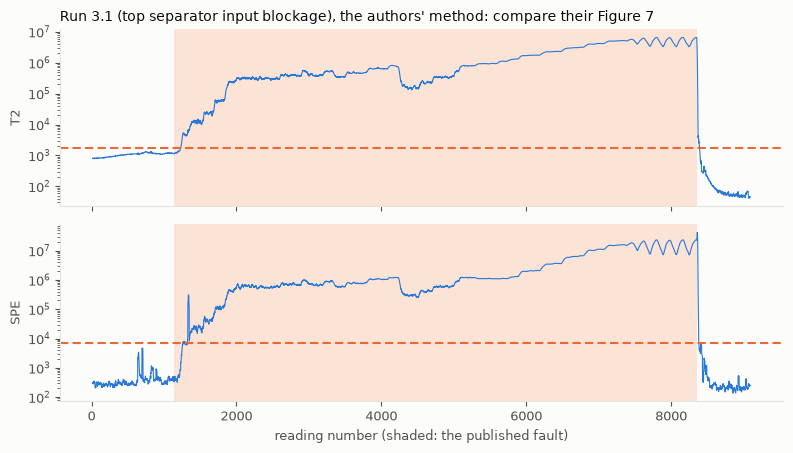

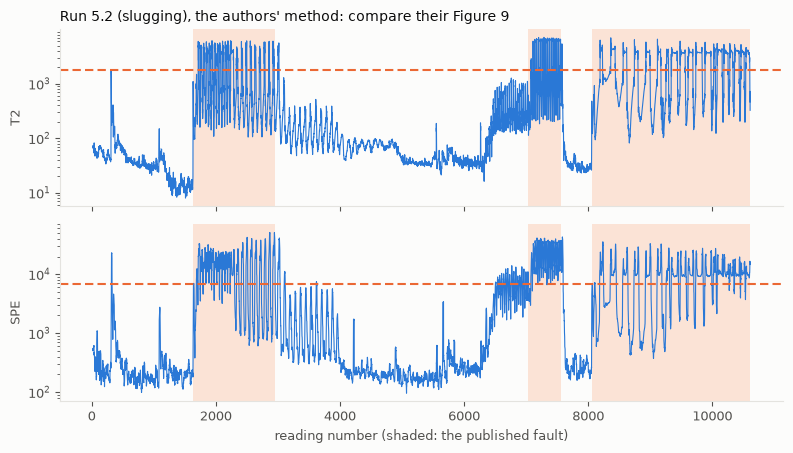

In [3]:
examples = [structure.cached(f"cranfield_cva_{k}", lambda k=k: cva.authors_example(k)) for k in ("3_1", "5_2")]
plots.cva_check(examples[0], "Run 3.1 (top separator input blockage), the authors' method: compare their Figure 7")
plots.cva_check(examples[1], "Run 5.2 (slugging), the authors' method: compare their Figure 9")
print("Alarm limits here:", explore.tidy(examples[0]["T2_limit"]), "and", explore.tidy(examples[0]["SPE_limit"]),
      "| in the paper (Table 10): 1753.97 and 6940.73")
cva.check_table(examples)

**Reading this**
- **The alarm limits match the paper to the last digit shown**: 1754 and 6941 here, 1753.97 and 6940.73 in the paper's Table 10.
- **Run 3.1:** the paper says the fault is first detected at reading 1230 by T2. Ours: 1230. For SPE the paper says 1324; ours first crosses briefly at 1261 and stays above from 1324. The shape of both curves matches the authors' figure: quiet before the fault, far above the limit throughout it, back below once the valve is reopened.
- **Run 5.2:** the paper gives T2 detections at readings 1716, 7075 and 8171 for the three bouts of slugging. Ours: 1716, 7075 and 8191. For SPE the paper gives 1643 and 8103; ours match both. (For the second bout the paper notes SPE was already above its limit before slugging began, which is what we see too.)

So the files, the 23 columns and the fault times are being read as the authors intend.

## 4. Normal running: 20 flow settings

The picture shows the water flow (blue) and air flow (orange) through each normal run. The flat steps are the flow settings. The table shows how many minutes each run spends at each of the 20 pairings.

Which setting each reading belongs to is worked out from the two flow readings themselves: a reading is "at" a setting when both flows are close to one of the rig's standard values, and "between settings" while a flow is being changed.

water flow,water 0.5 kg/s,water 1 kg/s,water 2 kg/s,water 3.5 kg/s,water 6 kg/s,water 0.5 kg/s,water 1 kg/s,water 2 kg/s,water 3.5 kg/s,water 6 kg/s,water 0.5 kg/s,water 1 kg/s,water 2 kg/s,water 3.5 kg/s,water 6 kg/s
run,T1,T1,T1,T1,T1,T2,T2,T2,T2,T2,T3,T3,T3,T3,T3
air 0.0208 Sm3/s,7.1,8.3,5,21.8,8,4.4,7.8,21.9,4.7,6.3,22.2,3.9,8.1,22.3,10.9
air 0.0278 Sm3/s,2.9,4.8,6.2,4.3,11.7,5.6,2.8,6.6,0,11.2,9.8,3.1,6.4,8,10.4
air 0.0347 Sm3/s,12.1,16.5,1.6,6.5,1.8,11.6,16.8,2.1,5.9,2.4,3.4,8.8,9.5,9.7,4.4
air 0.0417 Sm3/s,1.8,6.8,17.2,3.2,7.4,2,7.2,18,1.3,8.2,8.7,6.8,18.4,17.9,5.8


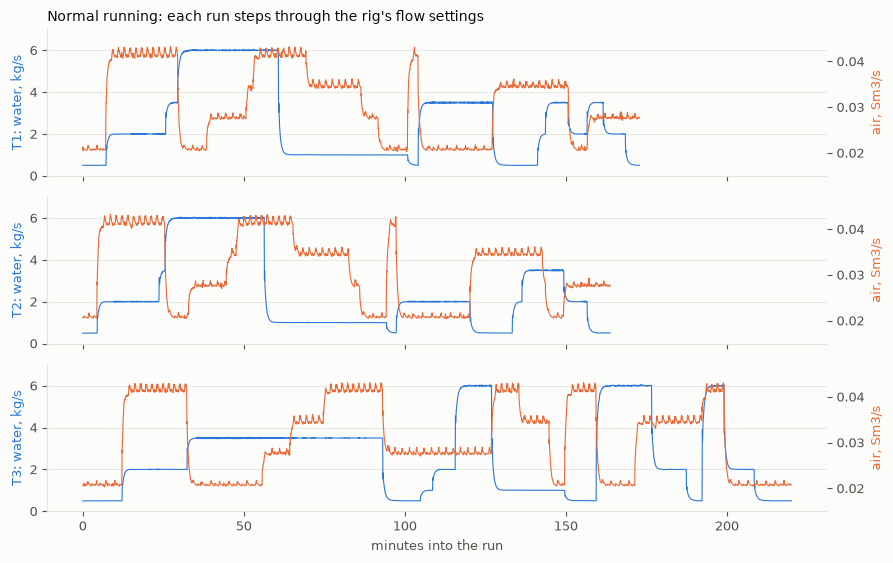

In [4]:
plots.flows_over_time(normal);
data.cranfield_settings_table()

**Reading this**
- Each run visits **each of the 20 settings about once** (T2 misses one), for anything from just over a minute to 22 minutes. About 10% of readings are taken between settings.
- T1 and T2 step through the settings in nearly the same order. T3 follows a different order.
- This matters for the next two sections. A run here is not "one setting", as it will be in the multi-mode chemical plant. Each run is a tour of all the settings.

## 5. Does one run dominate?

`04_delayed_links.ipynb` found that one unusual run can wreck the ranges. The rule fixed before looking at this data: check how each sensor's movement is spread over the runs, and if one run holds more than half of any sensor's movement, report results with and without it.

With three runs, an even spread would be 0.33 each.

In [5]:
structure.movement_by_run(list(normal.values()), rig.channels, list(normal)).sort_values("largest share", ascending=False).head(10)

,largest share,run,even share
sensor,,,
LI504,0.597,T3,0.333
FT104 temp,0.582,T3,0.333
FT406 temp,0.581,T3,0.333
FT407 temp,0.58,T3,0.333
FT104 density,0.546,T3,0.333
PT403,0.527,T3,0.333
PT408,0.527,T3,0.333
FT406 flow,0.521,T3,0.333
FT407 flow,0.5,T3,0.333


**Reading this**
- **T3 holds more than half the movement of eight sensors**, up to 60%. They are the three temperatures, the water density (which follows temperature), a separator level and three pressure and flow readings.
- The reason is plain in the data: on the day of T3 the water was about 7 degrees warmer (24 °C against 16 to 17 °C), and the level in the three-phase separator sat near 20% instead of 33%. T3 is a normal run on a different kind of day, not a faulty recording.
- So every pooled result below is given **twice: with all three runs, and with T1 and T2 only**.

**Which one is the headline.** The rule as first written would headline the version without T3. After the T1 + T2 number had been computed and reported (+2.8 points), the headline for the go/no-go rule was fixed as **all three runs**, with T1 + T2 beside it. That choice was made after seeing a result, so it is stated here. The two versions land on the same side of the +3 point mark.

## 6. How readings are held out

The curvature measure always scores models on readings they did not see. On the earlier datasets, each run was cut into five blocks of time and each block was held out in turn.

Here that would go wrong. Each run visits each setting once, so holding out a block of time holds out whole settings. The models would then be asked to guess at a flow setting they have never seen, which tests guessing, not curvature. The plan warned against exactly this.

So readings are held out as **whole visits to a setting, staggered across the runs**: when a setting's visit in one run is held out, the visits to that same setting in the other runs stay in the training data. Every setting and every run is then in the training data every time. This was decided before any curved share was computed for this rig. The table shows how much difference it makes.

In [6]:
pd.concat([cranfield.folds(), cranfield.folds(cranfield.WITHOUT_T3)])

,held-out readings at a setting never seen in training
"runs used, and how readings are held out",
T1 + T2 + T3: five blocks of time within each run,0.155
"T1 + T2 + T3: whole visits to a setting, staggered across runs",0
T1 + T2: five blocks of time within each run,0.638
"T1 + T2: whole visits to a setting, staggered across runs",0.014


**Reading this**
- With five blocks of time per run, **16% of held-out readings sit at a setting the models never saw** (64% with T1 and T2 only, because those two runs visit the settings in the same order).
- With staggered visits it is 0% (1.4% with T1 and T2 only: the one setting T2 never visits).

The block-of-time version is still reported in the next section, on its own row, so the two can be compared.

## 7. How curved are the links, all settings pooled?

This is the measure the go/no-go rule is about: all the normal readings pooled, each sensor predicted from the others' readings at the same moment.

Each row of the tables is one version of the measure:
- **same moment**: the go/no-go measure.
- **setting told to the straight model**: the straight-line model is also told which flow setting the rig is at, and may use a different level for each setting (but the same slopes). If the curved share falls, the curve was mostly levels shifting from setting to setting. If it stays, the links themselves bend.
- **blocks of time within each run**: the hold-out used on the earlier datasets (see section 6).
- **+ ... back**: the other sensors' past readings are offered too, as in `04_delayed_links.ipynb`. The first four rows reach 3, 6, 15 and 30 minutes back, the same span of time as on the chemical plant. The last reaches 1 to 10 seconds back, in case a rig this small has shorter delays. These choices were fixed before anything was measured.

Each curved share has two ranges. **(runs)** redraws whole runs, as the plan asks. With only three runs that can go few ways, so it is rough. **(visits)** redraws the 117 visits instead (76 for T1 + T2), and is the steadier guide.

First all three runs, then T1 and T2 only.

In [7]:
headline = cranfield.measures()
cranfield.measure_table(headline)

,straight share,curved share,"curved, low (runs)","curved, high (runs)","curved, low (visits)","curved, high (visits)",sensors gaining over 0.10 from curves,readings
measure,,,,,,,,
same moment (the go/no-go measure),0.839,0.022,0.018,0.023,0.015,0.029,3,33397
"same moment, setting told to the straight model",0.839,0.009,0.008,0.01,0.003,0.017,1,33397
"same moment, blocks of time within each run",0.811,0.021,0.014,0.023,0.013,0.03,2,33397
+ 3 min back,0.841,0.018,0.015,0.019,0.013,0.024,1,32857
"+ 3, 6 min back",0.836,0.015,0.012,0.015,0.008,0.022,1,32317
"+ 3, 6, 15 min back",0.829,0.014,0.012,0.017,0.01,0.018,1,30697
"+ 3, 6, 15, 30 min back",0.825,0.014,0.013,0.016,0.011,0.018,1,27997
"+ 1, 2, 5, 10 s back",0.858,0.015,0.01,0.017,0.009,0.022,2,33367


In [8]:
without_t3 = cranfield.measures(cranfield.WITHOUT_T3)
cranfield.measure_table(without_t3)

,straight share,curved share,"curved, low (runs)","curved, high (runs)","curved, low (visits)","curved, high (visits)",sensors gaining over 0.10 from curves,readings
measure,,,,,,,,
same moment (the go/no-go measure),0.813,0.028,0.013,0.037,0.019,0.038,3,20197
"same moment, setting told to the straight model",0.668,0.011,0.004,0.015,0.003,0.019,0,20197
"same moment, blocks of time within each run",0.754,0.025,0.013,0.03,0.017,0.032,1,20197
+ 3 min back,0.816,0.022,0.014,0.027,0.016,0.029,1,19837
"+ 3, 6 min back",0.791,0.014,0.01,0.018,0.008,0.021,1,19477
"+ 3, 6, 15 min back",0.808,0.011,0.006,0.015,0.007,0.015,0,18397
"+ 3, 6, 15, 30 min back",0.79,0,-0.002,0,-0.006,0.006,0,16597
"+ 1, 2, 5, 10 s back",0.834,0.016,0.006,0.022,0.008,0.023,1,20177


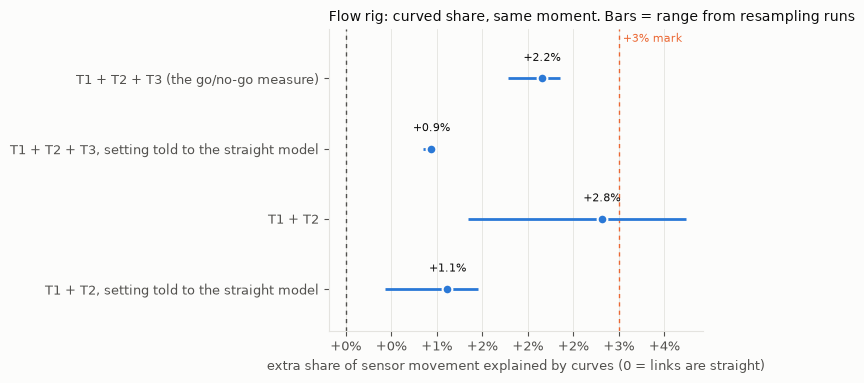

In [9]:
shown = {"T1 + T2 + T3 (the go/no-go measure)": headline[cranfield.SAME_MOMENT],
         "T1 + T2 + T3, setting told to the straight model": headline[cranfield.TOLD],
         "T1 + T2": without_t3[cranfield.SAME_MOMENT], "T1 + T2, setting told to the straight model": without_t3[cranfield.TOLD]}
plots.curved_share(shown, title="Flow rig: curved share, same moment. Bars = range from resampling runs", mark=0.03);

**Reading this**

*The go/no-go measure (all three runs, same moment)*
- **Straight share 0.84. Curved share +0.022**: range 0.018 to 0.023 redrawing runs, 0.015 to 0.029 redrawing visits.
- Against the rule fixed in the plan (go if the whole range lies above +3 points; no-go if it stays at or near zero): **both ranges lie wholly below +3 points.** The curved share is small but it is not zero: both ranges also stay clear of zero.
- With T1 and T2 only: +0.028, range 0.013 to 0.037 (runs) or 0.019 to 0.038 (visits). Those ranges straddle +3 points, so they are not wholly above it either.

*What the other rows add*
- **Telling the straight model the setting removes more than half the curved share**: +0.022 falls to +0.009 (range 0.003 to 0.017 redrawing visits). With T1 and T2 only: +0.028 falls to +0.011. So most of what looks curved when the settings are pooled is levels that shift from one setting to the next.
- **Blocks of time** give almost the same average (+0.021), though for a different reason in part: some of what it scores is guessing at unseen settings.
- **Past readings do not add curved share.** With past readings on offer it is between +0.014 and +0.018, a little lower than without them, at every reach from seconds to half an hour.

In [10]:
cranfield.separate_lines()

,"same moment, a separate straight model per setting"
"straight share, average",-31.527
worst sensor,-545.537
sensors with a straight share below 0,15
"curved share, average",0.036


**A stronger version that did not work.** "Telling the straight model the setting" was first built as a completely separate straight-line model for each setting, with its own slopes. The table above shows what happened: an average straight share far below zero, meaning its predictions were much worse than a flat line. The cause is that each setting has only one visit per run to learn from, and within a visit the sensors barely move, so the slopes are fitted to noise. The version used above (one model, with its own level per setting) was adopted after seeing this.

## 8. Which sensors carry the curved share?

The average hides a split. The picture shows every sensor's curved share (all three runs, same moment) with its range from redrawing visits. The dashed orange line is the 10-point mark the plan asks to be counted.

The second table shows, for the most curved sensors, what happens when the straight model is told the setting, and what the sensor's curved share is without T3.

,what it measures,straight,curved,"curved, low (runs)","curved, high (runs)","curved, low (visits)","curved, high (visits)"
sensor,,,,,,,
FT407 flow,Flow at the top of the riser,0.373,0.197,0.063,0.268,0.11,0.302
FT406 density,Density out of the top separator,0.632,0.177,0.111,0.219,0.105,0.259
FT406 flow,Flow out of the top separator,0.762,0.111,0.083,0.125,0.057,0.161
PT501,Pressure in the three-phase separator,0.775,0.037,0.011,0.081,0.012,0.072
FT104 density,Density of the water going in,0.916,0.028,0.022,0.044,0.018,0.037
PT403 diff,Pressure drop across valve VC404,0.878,0.018,0.016,0.021,0.012,0.026
FT407 density,Density at the top of the riser,0.886,0.015,0.013,0.017,0.008,0.021
LI504,Gas-liquid level in the three-phase separator,0.971,0.011,0.005,0.026,0.007,0.016
VC302,Position of valve VC302,0.992,0.003,0.003,0.004,0.002,0.004


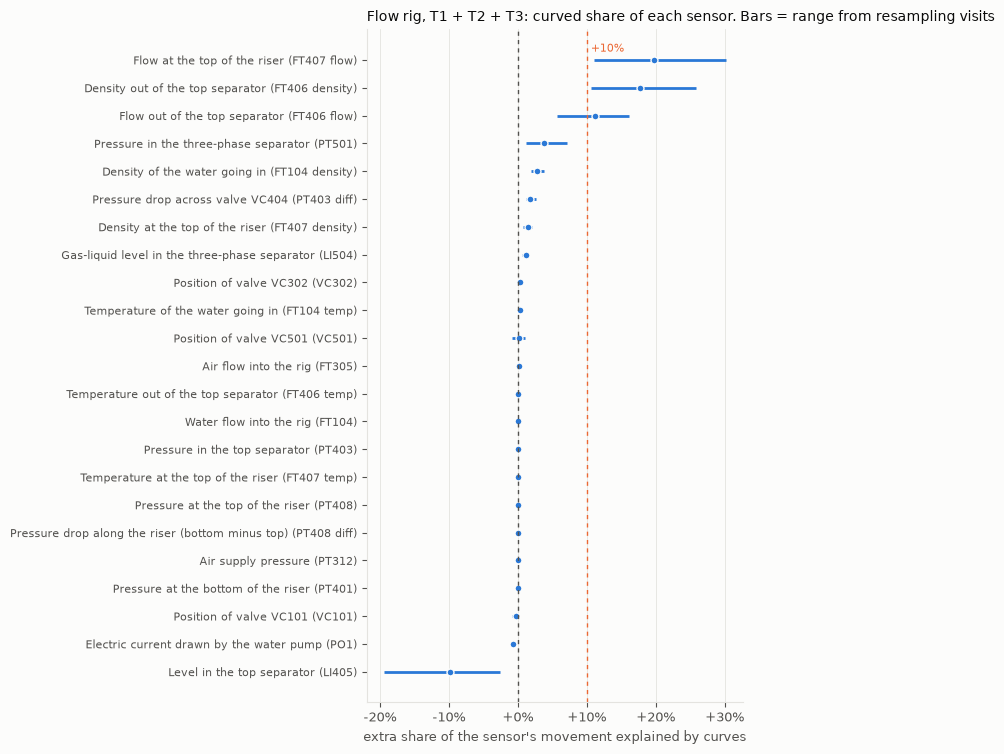

In [11]:
by_sensor = cranfield.sensor_table(headline)
plots.curved_by_sensor(by_sensor, "Flow rig, T1 + T2 + T3: curved share of each sensor. Bars = range from resampling visits");
by_sensor

In [12]:
pd.concat([by_sensor[["what it measures", "straight", "curved"]],
           cranfield.sensor_table(headline, cranfield.TOLD)[["straight", "curved"]].add_suffix(", setting told"),
           cranfield.sensor_table(without_t3)[["curved"]].add_suffix(", without T3")], axis=1).head(8)

,what it measures,straight,curved,"straight, setting told","curved, setting told","curved, without T3"
sensor,,,,,,
FT407 flow,Flow at the top of the riser,0.373,0.197,0.666,0.024,0.147
FT406 density,Density out of the top separator,0.632,0.177,0.493,0.139,0.05
FT406 flow,Flow out of the top separator,0.762,0.111,0.825,0.053,0.101
PT501,Pressure in the three-phase separator,0.775,0.037,0.739,0.023,0.124
FT104 density,Density of the water going in,0.916,0.028,0.852,0.036,0.097
PT403 diff,Pressure drop across valve VC404,0.878,0.018,0.886,0.01,0.011
FT407 density,Density at the top of the riser,0.886,0.015,0.905,-0.001,0.013
LI504,Gas-liquid level in the three-phase separator,0.971,0.011,0.958,0.016,0.065


**Reading this**
- **Three of the 23 sensors gain more than 10 points from curves**: the flow at the top of the riser (+20), the density out of the top separator (+18) and the flow out of the top separator (+11). All three are readings from the two flow meters around the top separator.
- **Most sensors gain nothing.** Fifteen of the 23 have a curved share under 1 point, and for most of those the straight share is already above 0.99: pressures, valve positions and the two input flows are almost perfectly predicted by straight lines.
- **Told the setting, two of the three shrink sharply.** The flow at the top of the riser falls from +20 to +2, and the flow out of the top separator from +11 to +5. Their "curves" were mostly different levels at different settings. The density out of the top separator keeps most of its curved share (+14). Section 9 shows why.
- **Which three depends on the runs used.** Without T3 the density out of the top separator is at +5, and a separator pressure takes its place above 10 points. Only the two flow readings are above 10 points both ways.
- The level in the top separator has a negative curved share (about -10): the flexible model makes it worse.

## 9. Real curves, or separate clusters?

A curved share can come from two quite different things. One is a **real curve**: as one sensor rises, another follows along a bent line, and readings from every setting sit along that same line. The other is **separate clusters**: each flow setting puts the sensors at its own spot, the spots do not line up, and a flexible model simply learns where each spot is.

To tell them apart, each of the three sensors above is plotted against the one other sensor that says most about it. Every dot is a reading. The same dots are coloured twice: by water flow setting on the left, by air flow setting on the right. Grey dots are readings taken between settings.

The small table first shows which other sensor was picked, and what share of the sensor's movement that one sensor explains on its own.

,best single predictor,share explained
sensor,,
FT407 flow,PT408 diff,0.493
FT406 density,VC101,0.799
FT406 flow,PT401,0.849


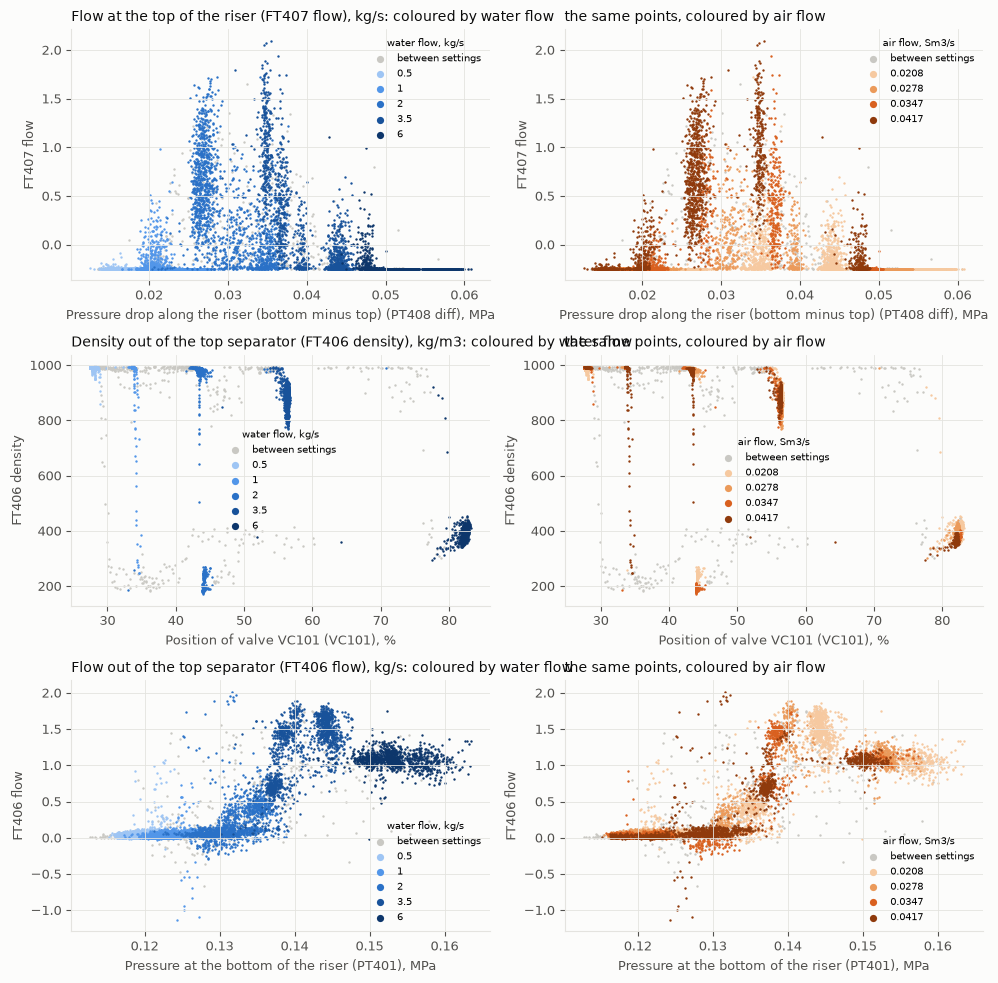

In [13]:
display(cranfield.best_partner(sensors=cranfield.most_curved(headline)))
cranfield.curved_scatter(headline);

**Reading this**

- **Flow at the top of the riser (top row).** For most readings this meter sits at the very bottom of its range, the flat line of dots at about -0.25. At a few settings (water at 2 or 3.5 kg/s with the higher air flows) it jumps and scatters upward in a tall narrow column. There is no bent line here. This is a meter that reads its floor at most settings and comes alive at a few: separate clusters.
- **Density out of the top separator (middle row).** Each water flow setting puts the water valve at its own position, giving five narrow columns. Within a column the density is either near 1,000 kg/m3 (plain water) or far lower, 200 to 400 (water with a lot of air in it), with little in between. At the highest water flow it is always low. This is a reading that **flips between two states**, not a curve. It also explains section 8: telling a straight model the setting cannot help when the flip happens within a setting.
- **Flow out of the top separator (bottom row).** This is the nearest to a bent line: zero at the low water flows, rising steeply around the middle, then levelling off near 1.0 at the highest. But the dots are five blobs, one per water flow setting, and within each blob there is no slope. The bend is traced by the positions of the blobs, which is why telling the straight model the setting removes half of it.

So none of the three shows a smooth curve followed by readings from all settings. What a flexible model gains here is mostly knowing **which setting, or which of two states, the rig is in**.

## 10. Inside each setting

The plan also asks for the measure inside each setting on its own, where the links were expected to look straight.

For each of the 20 settings, the data is its visits from the runs, each with its own average level removed, so what is left is how the sensors move around their level while the setting is held. Each visit is cut into five blocks of time and each block is predicted from the rest, as was done for the pump's sessions.

The first table summarises the 20 settings. The second lists them.

In [14]:
inside = cranfield.within_settings()
display(pd.DataFrame({"T1 + T2 + T3": cranfield.within_summary(inside),
                      "T1 + T2": cranfield.within_summary(cranfield.within_settings(cranfield.WITHOUT_T3)),
                      "first design, dropped: whole visits held out (T1 + T2 + T3)":
                          cranfield.within_summary(cranfield.within_settings(whole_visits=True))}))
inside

,T1 + T2 + T3,T1 + T2,"first design, dropped: whole visits held out (T1 + T2 + T3)"
settings,20,19,20
"straight share, middle setting",0.001,-0.361,-5.991
"curved share, middle setting",-0.057,0.002,-0.105
"curved share, most curved setting",0.077,0.049,0.255
settings with a curved share above 0.03,4,2,2


,visits,readings,straight share,curved share,"curved, low","curved, high",sensors gaining over 0.10 from curves
setting,,,,,,,
"air 0.0208, water 0.5",4,2021,0.334,-0.051,-0.096,-0.028,1
"air 0.0208, water 1",3,1201,-1.91,0.024,-1.075,0.082,3
"air 0.0208, water 2",3,2097,0.029,-0.086,-0.365,0.044,2
"air 0.0208, water 3.5",3,2930,0.091,0.056,0.038,0.219,6
"air 0.0208, water 6",3,1514,-10.521,0.077,0.066,0.55,5
"air 0.0278, water 0.5",3,1099,0.16,0.008,-0.006,0.563,3
"air 0.0278, water 1",3,644,-0.368,-0.056,-13.01,0.095,3
"air 0.0278, water 2",3,1152,-0.177,-0.092,-0.126,-0.068,1
"air 0.0278, water 3.5",2,738,0.111,-0.07,-0.134,0.009,2


**Reading this**
- **Inside a held setting, the sensors say almost nothing about each other.** The middle setting has a straight share of 0.00. Once the flows are held steady, what is left is mostly each sensor's own noise.
- **Curves add nothing in the typical setting**: the middle curved share is -0.06, and no setting is above +0.08. Four settings of the 20 have a curved share above +0.03.
- **These numbers are rough, and should not be read finely.** Each setting has only two to four visits, so the ranges are very wide. Some sensors barely move within a setting, and a share of a very small movement swings wildly, which is where the large negative straight shares in a few rows come from. The count of "sensors gaining over 0.10" in a row is not reliable for the same reason.
- Without T3 the curved shares are just as small: +0.00 in the middle setting, +0.05 in the most curved one.

**A design that was dropped.** The first version held out each visit whole and predicted it from the other visits. That failed (last column of the first table: a middle straight share far below zero): the small movements around a held setting differ from visit to visit, so models fitted on other visits do worse than a flat line. The block-of-time version shown here was adopted after seeing that.

So within a setting there is no sign of curved links, and little sign of links of any kind. The links on this rig live **between** settings.

## 11. The eight detectors on the 16 faulty runs

Every detector learns "normal" from runs T2 and T3 (the pair the paper's authors train on), then scores the 16 faulty runs. No detector setting was changed for this data.

As planned before scoring, the alarm line was to come from T1, the normal run the detectors never see, placed to allow 1 false alarm in 100 there. The catch rate under each run's own line (set on that run's own normal readings, as for the pump) was to be shown beside it.

The first table shows both. Its middle column is a check on the T1 line: the share of the faulty runs' **own normal readings** that cross it. If the line carries over, that is about 0.01. The second table splits those false alarms into before the fault and after it.

In [15]:
run.score_all(datasets=[rig])
pair = structure.cached("cranfield_report", lambda: run.report_two_lines(rig))
run.two_lines_table(pair)

,"caught, line from separate normal data",false alarms on the runs' own normal readings,"caught, each run's own line"
detector,,,
Curved-link residual,0.88 (0.75-0.97),0.575,0.37 (0.26-0.50)
Straight-link residual,0.86 (0.72-0.95),0.475,0.38 (0.27-0.51)
Matrix Profile,0.75 (0.60-0.87),0.525,0.25 (0.14-0.38)
PCA (T2 + SPE),0.69 (0.51-0.82),0.275,0.26 (0.15-0.39)
CUSUM chart,0.57 (0.36-0.72),0.453,0.20 (0.08-0.32)
EWMA chart,0.54 (0.32-0.71),0.155,0.24 (0.13-0.37)
Rolling z-score,0.54 (0.32-0.71),0.148,0.23 (0.12-0.36)
Isolation Forest,0.21 (0.15-0.37),0.074,0.12 (0.04-0.20)


In [16]:
run.false_alarms_around_fault(rig)

,false alarms before the fault,false alarms after the fault,runs with over 0.05 before the fault,runs
detector,,,,
Rolling z-score,0.074,0.218,4,16
EWMA chart,0.073,0.232,4,16
CUSUM chart,0.031,0.851,1,16
PCA (T2 + SPE),0.094,0.446,6,16
Isolation Forest,0.054,0.099,2,16
Matrix Profile,0.421,0.623,10,16
Straight-link residual,0.518,0.434,10,16
Curved-link residual,0.641,0.513,12,16


**Reading this**

**The line from T1 does not carry over, so its catch rates cannot be used.**
- Under it the two link detectors appear to catch 86% and 88% of fault readings. But 48% and 58% of the same runs' *normal* readings cross the line too. That is not "1 false alarm in 100".
- **The false alarms are there before any fault starts** (second table): 52% and 64% for the link detectors, 42% for Matrix Profile. In 10 to 12 of the 16 runs, more than 5% of the readings before the fault are already above the line. So this is not the rig taking time to settle after a fault.
- The cause is that the faulty runs were recorded on days that look different from the normal runs. For example, in five of the seven runs where the straight-link detector is above the line from the first reading, the three-phase separator level sits at 3% to 13%; in the three normal runs it is between 20% and 33%. A detector that has learned the links between 23 sensors on two days treats such a day as abnormal throughout.
- The other five detectors are less affected: 3% to 9% of readings before the fault cross their lines.

**Under each run's own line, which does hold 1 false alarm in 100 on that run's normal readings:**
- **Straight-link residual 0.38 (0.27 to 0.51), curved-link residual 0.37 (0.26 to 0.50).** Then PCA 0.26, Matrix Profile 0.25, EWMA 0.24, rolling z-score 0.23, CUSUM 0.20, Isolation Forest 0.12.
- These are low next to the chemical plant's 0.8. Two reasons: the faults are applied step by step, so much of each labelled fault is mild; and each run's own line is pushed up by whatever its normal readings contain.

Presenting each run's own line as the fair comparison was decided after seeing the T1 line fail its check.

In [17]:
steady = [r.meta["flow settings"] == "steady" for r in rig.runs]
calm = structure.cached("cranfield_report_steady",
                        lambda: run.report_dataset(rig, list(run.METHODS), 5, 1000, keep=steady, calibration="per_run", verbose=False))
display(run.rates(calm).to_frame("caught, each run's own line, the 8 steady-flow runs"))
display(run.gap_table(pair["other"], "Straight-link residual"))
run.gap_table(calm, "Straight-link residual")

,"caught, each run's own line, the 8 steady-flow runs"
detector,
Straight-link residual,0.31 (0.21-0.49)
Curved-link residual,0.30 (0.19-0.48)
PCA (T2 + SPE),0.24 (0.10-0.41)
Matrix Profile,0.22 (0.08-0.39)
Rolling z-score,0.20 (0.05-0.38)
EWMA chart,0.19 (0.05-0.37)
CUSUM chart,0.06 (0.00-0.14)
Isolation Forest,0.02 (0.00-0.04)


,gap,low,high,verdict
Straight-link residual against,,,,
Rolling z-score,0.156,0.1,0.221,ahead
EWMA chart,0.148,0.09,0.212,ahead
CUSUM chart,0.189,0.007,0.369,ahead
PCA (T2 + SPE),0.126,0.056,0.203,ahead
Isolation Forest,0.276,0.13,0.408,ahead
Matrix Profile,0.137,0.076,0.208,ahead
Curved-link residual,0.014,0.002,0.028,tie


,gap,low,high,verdict
Straight-link residual against,,,,
Rolling z-score,0.118,0.053,0.184,tie
EWMA chart,0.125,0.062,0.188,ahead
CUSUM chart,0.253,0.102,0.417,ahead
PCA (T2 + SPE),0.071,0.001,0.138,tie
Isolation Forest,0.291,0.193,0.437,ahead
Matrix Profile,0.095,0.048,0.147,tie
Curved-link residual,0.014,0.001,0.027,tie


**Which gaps are real wins?** The rule is unchanged: a detector is "ahead" only if the gap is at least 12 points and its range does not include zero.

*All 16 runs, each run's own line (second table)*
- The straight-link detector is **ahead** of every detector except the curved-link one: by 13 points over PCA (range 6 to 20) and 14 over Matrix Profile (8 to 21).
- **Straight-link and curved-link tie**: a gap of 1.4 points. Allowing curves does not help detection here.

*The 8 runs at steady flows (first and third tables)*
- Each run's own line has a weakness in the other 8 runs: their flow settings keep changing, so the normal readings that set the line may be at different settings from the fault. In the 8 steady-flow runs the flows are held, so the line is fair. This split was added after seeing the results.
- There the order is the same, straight-link 0.31 (0.21 to 0.49), but its gaps to PCA (7 points), Matrix Profile (10) and the rolling z-score (just under 12) are **ties**. With 8 runs the ranges are wide.

So on this rig the link detectors are the best or tied for best, as on the chemical plant and the pump, and the curved version is no better than the straight one.

## 12. What kind of fault is each fault?

The first table is each detector's catch rate on each of the six kinds of fault (each run's own line). The second labels each fault the same way as in `02_how_curved.ipynb`: by which family of checks can see it.

In [18]:
display(run.fault_table(pair["other"]))
structure.fault_types(rig, saved=True, calibration="per_run")

,Straight-link residual,Curved-link residual,PCA (T2 + SPE),Matrix Profile,EWMA chart,Rolling z-score,CUSUM chart,Isolation Forest
kind of fault,,,,,,,,
1 Air line blockage,0.4,0.4,0.26,0.23,0.24,0.24,0,0.05
2 Water line blockage,0.22,0.21,0.11,0.09,0,0,0,0
3 Top separator input blockage,0.71,0.71,0.75,0.66,0.68,0.69,0,0.07
4 Open direct bypass,0.3,0.26,0.03,0.06,0.05,0.06,0.38,0
5 Slugging conditions,0.32,0.32,0.22,0.3,0.26,0.23,0.3,0.2
6 Pressurisation of the 2-inch line,0.31,0.27,0.13,0.11,0.19,0.12,0.7,0.48


,level checks,straight links,curved links,shape in time,sensors moved,kind
kind of fault,,,,,,
1 Air line blockage,0.236,0.396,0.396,0.232,0.3,hard for all
2 Water line blockage,0,0.216,0.206,0.089,0.3,hard for all
3 Top separator input blockage,0.69,0.75,0.714,0.66,2.7,single sensor
4 Open direct bypass,0.375,0.301,0.26,0.061,0.3,hard for all
5 Slugging conditions,0.3,0.324,0.324,0.3,4,hard for all
6 Pressurisation of the 2-inch line,0.698,0.312,0.273,0.113,5,many sensors


**Reading this**
- **Only fault 3 (blocking the top separator inlet) is caught by most detectors**, at about 0.7. It moves a few sensors a long way, so it is labelled a single-sensor fault.
- **Faults 1, 2, 4 and 5 are labelled "hard for all"**: under each run's own line nothing catches half of their readings. The link detectors do best on the air-line blockage (0.40) and the water-line blockage (0.22), where the per-sensor checks catch less or nothing. The pattern from the chemical plant, that some faults show only in the links, appears here too, but weakly.
- **Fault 6 should be ignored.** It is the fault that was designed not to show in these 23 sensors (section 1). The 0.70 that CUSUM scores on it is not the fault. Those two runs have no normal readings after the fault begins, so each run's line is set on the first part of the run only, and the flow settings then change. It is the same flaw that `03_fresh_runs.ipynb` found on the chemical plant.

This rig is a much harder and messier test of detectors than the chemical plant: faults that build up gradually, normal days that differ from each other, and only 16 runs.

## 13. What this means

| Measure (pooled, same moment) | Curved share | Range, redrawing runs | Range, redrawing visits | Sensors gaining over 10 points |
|---|---|---|---|---|
| **All three normal runs (the go/no-go measure)** | **+0.022** | 0.018 to 0.023 | 0.015 to 0.029 | 3 of 23 |
| The same, setting told to the straight model | +0.009 | 0.008 to 0.010 | 0.003 to 0.017 | 1 of 23 |
| T1 and T2 only | +0.028 | 0.013 to 0.037 | 0.019 to 0.038 | 3 of 23 |
| T1 and T2 only, setting told to the straight model | +0.011 | 0.004 to 0.015 | 0.003 to 0.019 | 0 of 23 |

- **Against the rule fixed in the plan:** the go/no-go measure's range lies wholly below +3 points, so on this rig the condition for "go" is not met. The curved share is also not zero. The decision itself waits for the multi-mode chemical plant (`06_multimode_tep.ipynb`) and is not made here.
- **Running a machine at many settings did produce some curved share**, where two single-setting datasets produced none. But most of it is levels that differ between settings, which a straight model handles once it is told the setting.
- **It sits in three sensors**, and their pictures show clusters, a meter at the bottom of its range and a reading that flips between two states. No smooth curve.
- **Within a setting** there is no sign of curved links.
- **For detection**, the curved-link detector ties with the straight-link one, as it has on every dataset so far.

**Choices made after seeing results** (each is also noted where it is used)
- The headline for the go/no-go rule uses all three normal runs. This was fixed after the T1 + T2 number was known. The outlier-run rule as first written would have headlined T1 + T2. Both are in the table and neither range is wholly above +3 points.
- "Setting told to the straight model" means one straight model with its own level per setting. A separate model per setting was tried first and gave nonsense.
- Inside each setting, blocks of time within each visit are held out. Holding out whole visits was tried first and failed.
- Each run's own alarm line is presented as the fair comparison for the detectors, because the planned line from T1 failed its own check. The steady-flow split was added afterwards.

**Fixed before any result was seen:** the 23 columns, the fault times, the staggered hold-out, the lags, fitting the detectors on T2 and T3, and every detector setting.

**What this does not cover**
- Only three normal runs, all from one rig. The range from redrawing runs is rough for that reason.
- Fault 6, which needs the column that was left out.
- One mismatch between the paper and the data is unresolved: the start of the fault in run 2.1.